<a href="https://colab.research.google.com/github/gabriel-schiavo/analise-acidentes-poa/blob/main/analise_acidentes_poa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Acidentes de trânsito em Porto Alegre: dá para prever se houve vítima?
**Grupo**: DataCore - Artur Diel, Gabriel Schiavo, Lucas Zimmermann, Vitor Mankowski

**Repositório GitHub**: https://github.com/gabriel-schiavo/analise-acidentes-poa

O objetivo deste trabalho é usar os dados abertos de acidentes de trânsito da Prefeitura de Porto Alegre (cerca de 87 mil acidentes, de 2021 a 2026) para descobrir o que está ligado a um acidente ter vítimas (feridos ou mortos) e responder à pergunta: sabendo quais veículos se envolveram, se era dia ou noite e se era fim de semana, dá para prever se o acidente teve vítima? Para isso, os dados são limpos e analisados com pandas e matplotlib e depois usados para treinar um modelo KNN do scikit-learn, cuja acurácia é comparada com o chute de dizer sempre "sem vítima".

## 1. Obtenção dos dados
Os dados são lidos direto da URL do portal de dados abertos da Prefeitura, então o notebook roda sem anexar arquivo.

In [1]:
import pandas as pd

In [2]:
csv_url = 'https://dadosabertos.poa.br/dataset/d6cfbe48-ee1f-450f-87f5-9426f6a09328/resource/b56f8123-716a-4893-9348-23945f1ea1b9/download/cat_acidentes.csv'

df = pd.read_csv(csv_url, sep=";")

## 2. Inspeção inicial
Tamanho da tabela, tipos de dados e valores vazios por coluna.

In [3]:
print(f"linhas: {df.shape[0]}")
print(f"colunas: {df.shape[1]}")

print(df.head())

print("Tipos de dados de cada coluna")
print(df.dtypes)

print("Valores vazios em cada coluna:")
print(df.isnull().sum())

linhas: 87323
colunas: 34
         data_extracao  predial1  queda_arr                 data  feridos  \
0  2026-10-01 01:34:27    2596.0        0.0  2021-01-02 00:00:00        6   
1  2026-10-01 01:34:27    3659.0        0.0  2021-01-03 00:00:00        1   
2  2026-10-01 01:34:27       0.0        0.0  2021-01-03 00:00:00        1   
3  2026-10-01 01:34:27    4879.0        0.0  2021-01-04 00:00:00        1   
4  2026-10-01 01:34:27    2500.0        0.0  2021-01-03 00:00:00        1   

   feridos_gr  mortes  morte_post  fatais  auto  ...  longitude   latitude  \
0           0       0           0       0     3  ... -51.119179 -30.014936   
1           0       0           0       0     1  ... -51.157411 -30.162425   
2           0       0           0       0     1  ... -51.195553 -29.975734   
3           0       0           0       0     0  ... -51.097502 -30.012522   
4           0       0           0       0     1  ... -51.229493 -30.049345   

                             log1  log2   

## 3. Limpeza
Removemos colunas que não serão usadas, linhas com valores vazios (principalmente sem hora), datas impossíveis (ano > 2026) e acidentes com tipo "NAO CADASTRADO". A contagem de linhas é mostrada a cada passo.

In [4]:
linhas_antes = df.shape[0]

df['data'] = pd.to_datetime(df['data'])
df['ano'] = df['data'].dt.year

colunas_descartadas = ['data_extracao', 'idacidente', 'predial1', 'log1', 'log2', 'consorcio', 'longitude', 'latitude', 'queda_arr', 'outro']
df = df[df.columns.difference(colunas_descartadas)]

df = df.dropna()
print(f'depois de remover os sem hora: {df.shape[0]}')

df = df[df["ano"] <= 2026]
print(f"depois de remover as datas impossíveis: {df.shape[0]}")

df = df[df["tipo_acid"] != "NAO CADASTRADO"].copy()
print(f"depois de remover os NAO CADASTRADO: {df.shape[0]}")

print(f"linhas antes: {linhas_antes}")
print(f"linhas depois: {df.shape[0]}")
print(f"colunas depois: {df.shape[1]}")
print(df.isnull().sum())

depois de remover os sem hora: 86476
depois de remover as datas impossíveis: 86472
depois de remover os NAO CADASTRADO: 83948
linhas antes: 87323
linhas depois: 83948
colunas depois: 25
ano           0
auto          0
bicicleta     0
caminhao      0
carroca       0
cont_vit      0
data          0
dia_sem       0
fatais        0
feridos       0
feridos_gr    0
hora          0
lotacao       0
morte_post    0
mortes        0
moto          0
noite_dia     0
onibus_int    0
onibus_met    0
onibus_urb    0
patinete      0
regiao        0
taxi          0
tipo_acid     0
ups           0
dtype: int64


## 4. Novas colunas
Criamos `noite` (1 = noite), `fim_de_semana` (1 = sábado ou domingo) e `hora_cheia` (0 a 23).

In [23]:
# 1 quando noite_dia é NOITE e 0 quando é DIA
noite = []
for turno in df["noite_dia"]:
    if turno == "NOITE":
        noite.append(1)
    else:
        noite.append(0)
df["noite"] = noite

# fim_de_semana 1 para sábado ou domingo e 0 para a semana
fim_de_semana = []
for dia in df["dia_sem"]:
    if dia == "SÁBADO" or dia == "DOMINGO":
        fim_de_semana.append(1)
    else:
        fim_de_semana.append(0)
df["fim_de_semana"] = fim_de_semana

# conversao para hora cheia
hora_cheia = []
for hora in df["hora"]:
    hora_cheia.append(int(hora[:2]))
df["hora_cheia"] = hora_cheia

print("acidentes à noite:", df["noite"].sum())
print("acidentes no fim de semana:", df["fim_de_semana"].sum())
print("menor hora:", df["hora_cheia"].min())
print("maior hora:", df["hora_cheia"].max())
print(f"colunas: {df.shape[1]}")
print(df[["noite_dia", "noite", "dia_sem", "fim_de_semana", "hora", "hora_cheia"]].head())

acidentes à noite: 23668
acidentes no fim de semana: 15929
menor hora: 0
maior hora: 23
colunas: 29
  noite_dia  noite        dia_sem  fim_de_semana              hora  hora_cheia
0       DIA      0         SÁBADO              1  12:30:00.0000000          12
1       DIA      0        DOMINGO              1  12:40:00.0000000          12
2     NOITE      1        DOMINGO              1  21:00:00.0000000          21
3       DIA      0  SEGUNDA-FEIRA              0  07:30:00.0000000           7
4       DIA      0        DOMINGO              1  11:00:00.0000000          11
0.9999880878639158


## 5. Alvo (y) e características (X)
- **y (`vitima`)**: 1 se houve algum ferido ou morto, 0 caso contrário.
- **X**: só os veículos envolvidos, `noite` e `fim_de_semana`.

`feridos`, `mortes`, `cont_vit` e similares ficam **fora do X** porque o alvo é calculado a partir delas (daria a resposta ao modelo).

In [6]:
import matplotlib.pyplot as plt

df["vitima"] = ((df["feridos"] + df["feridos_gr"] + df["mortes"]
                 + df["morte_post"] + df["fatais"]) > 0).astype(int)

veiculos = ["auto", "taxi", "lotacao", "onibus_urb", "onibus_met", "onibus_int",
            "caminhao", "moto", "carroca", "bicicleta", "patinete"]
X = df[veiculos + ["noite", "fim_de_semana"]]
y = df["vitima"]

print(X.shape, y.shape)

(83948, 13) (83948,)


### 5.1 Verificação: por que `cont_vit` e `ups` ficam fora do X
Se essas colunas já "contêm" a resposta, usá-las no modelo seria vazamento de informação. Para conferir, comparamos cada uma com o alvo `vitima`.

In [25]:
# Verifica se cont_vit é praticamente igual ao alvo (se for, é vazamento e fica fora do X)
print(((df["cont_vit"] > 0).astype(int) == df["vitima"]).mean())

0.9999880878639158


## 6. Análise exploratória
Para cada pergunta, uma tabela e um gráfico. Nas perguntas 3 a 7 usamos a mesma função: **% de acidentes com vítima** em cada grupo (percentual, para comparar grupos de tamanhos diferentes).

### 6.1 Acidentes com e sem vítima

Sem vítima    64.7
Com vítima    35.3
Name: proportion, dtype: float64


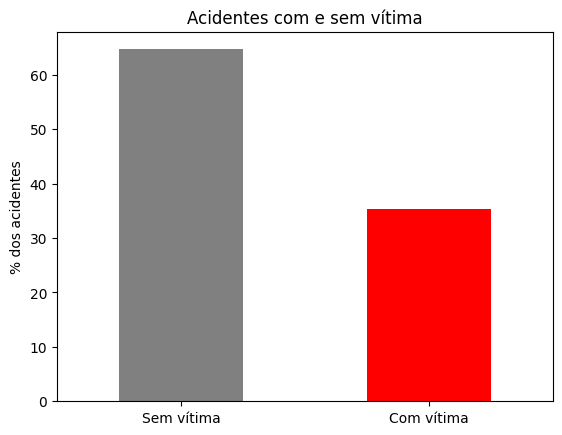

In [7]:
t1 = (df["vitima"].value_counts(normalize=True) * 100).round(1)
t1.index = ["Sem vítima" if i == 0 else "Com vítima" for i in t1.index]
print(t1)

t1.plot(kind="bar", color=["gray", "red"])
plt.ylabel("% dos acidentes"); plt.title("Acidentes com e sem vítima")
plt.xticks(rotation=0); plt.show()

### 6.2 % com vítima por tipo de veículo
Considera os acidentes em que aquele veículo se envolveu.

            acidentes  pct_com_vitima
taxi              909            12.7
caminhao         6734            13.4
lotacao           492            21.5
onibus_int        802            27.6
auto            76246            30.7
onibus_urb       2915            38.0
onibus_met        422            44.3
moto            24771            76.6
carroca            18            77.8
patinete           66            80.3
bicicleta        1525            90.4


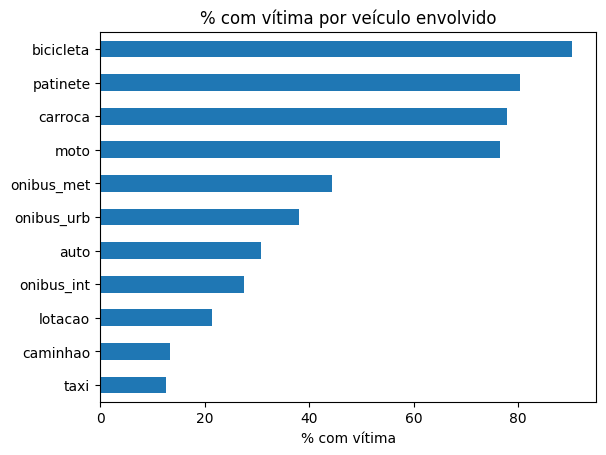

In [8]:
t2 = pd.DataFrame({
    "acidentes": {v: int((df[v] > 0).sum()) for v in veiculos},
    "pct_com_vitima": {v: round(df.loc[df[v] > 0, "vitima"].mean() * 100, 1) for v in veiculos},
}).sort_values("pct_com_vitima")
print(t2)

t2["pct_com_vitima"].plot(kind="barh")
plt.xlabel("% com vítima"); plt.title("% com vítima por veículo envolvido"); plt.show()

### 6.3 Dia x noite

noite_dia
DIA      31.5
NOITE    45.0
Name: vitima, dtype: float64


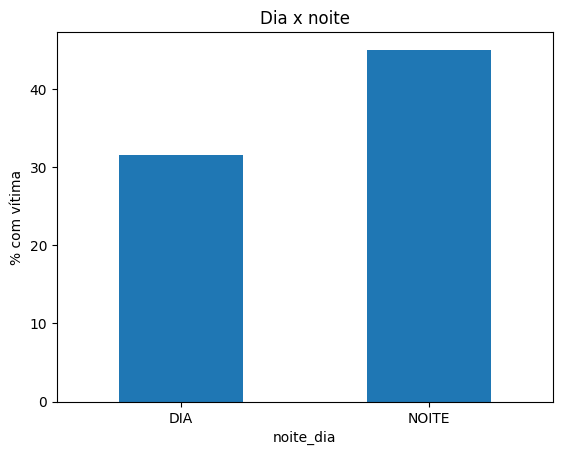

In [9]:
def pct_vitima(coluna):
    return (df.groupby(coluna)["vitima"].mean() * 100).round(1)

t3 = pct_vitima("noite_dia")
print(t3)
t3.plot(kind="bar"); plt.ylabel("% com vítima"); plt.title("Dia x noite")
plt.xticks(rotation=0); plt.show()

### 6.4 Fim de semana e dia da semana

fim_de_semana
0    33.6
1    42.6
Name: vitima, dtype: float64
dia_sem
SEGUNDA-FEIRA    33.3
TERÇA-FEIRA      33.4
QUARTA-FEIRA     33.6
QUINTA-FEIRA     33.4
SEXTA-FEIRA      34.3
SÁBADO           41.9
DOMINGO          43.6
Name: vitima, dtype: float64


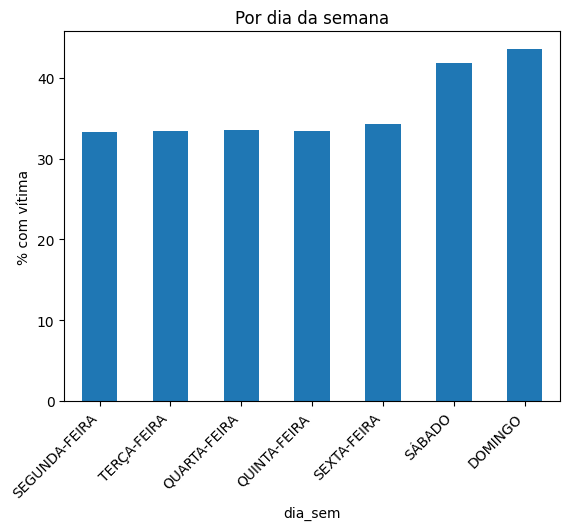

In [10]:
print(pct_vitima("fim_de_semana"))   # 0 = dia útil, 1 = fim de semana

ordem = ["SEGUNDA-FEIRA", "TERÇA-FEIRA", "QUARTA-FEIRA", "QUINTA-FEIRA",
         "SEXTA-FEIRA", "SÁBADO", "DOMINGO"]
t4 = pct_vitima("dia_sem")
t4 = t4.reindex([d for d in ordem if d in t4.index])
print(t4)

t4.plot(kind="bar"); plt.ylabel("% com vítima"); plt.title("Por dia da semana")
plt.xticks(rotation=45, ha="right"); plt.show()

### 6.5 Por horário

hora_cheia
0     46.9
1     47.8
2     45.4
3     41.7
4     39.3
5     41.9
6     39.0
7     37.3
8     32.1
9     28.5
10    25.9
11    28.1
12    32.6
13    33.5
14    30.3
15    29.8
16    32.3
17    33.2
18    39.6
19    44.9
20    47.4
21    52.3
22    49.7
23    50.1
Name: vitima, dtype: float64


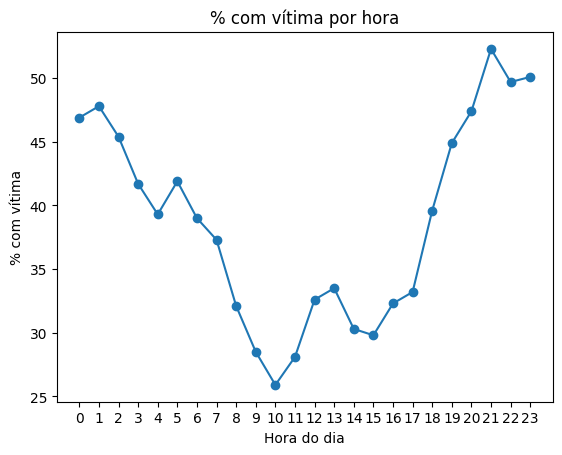

In [11]:
t5 = pct_vitima("hora_cheia")
print(t5)

t5.plot(marker="o"); plt.xticks(range(0, 24))
plt.xlabel("Hora do dia"); plt.ylabel("% com vítima"); plt.title("% com vítima por hora"); plt.show()

### 6.6 Por região

regiao
CENTRO    26.8
LESTE     35.4
NORTE     35.3
SUL       40.1
Name: vitima, dtype: float64


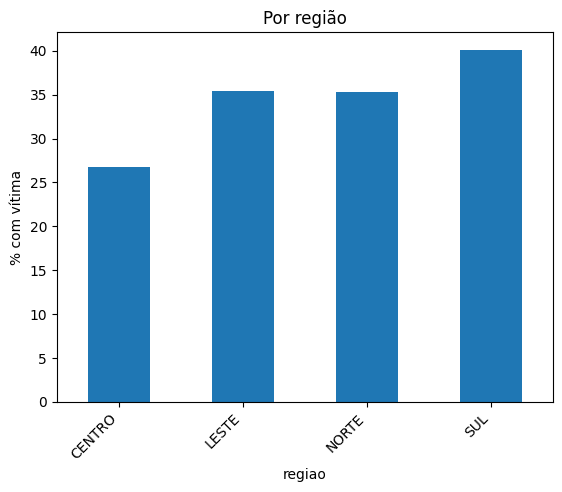

In [12]:
t6 = pct_vitima("regiao")
print(t6)

t6.plot(kind="bar"); plt.ylabel("% com vítima"); plt.title("Por região")
plt.xticks(rotation=45, ha="right"); plt.show()

### 6.7 Por ano
**Atenção:** 2026 é parcial (dados extraídos em outubro), por isso usamos percentual e não contagem.

ano
2021    36.4
2022    35.6
2023    36.9
2024    37.3
2025    33.2
2026    32.6
Name: vitima, dtype: float64


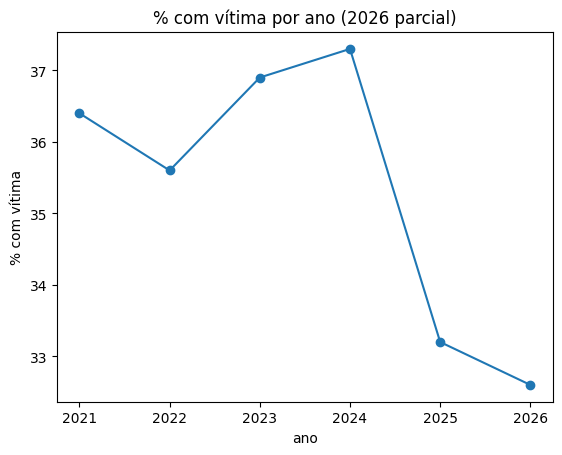

In [13]:
t7 = pct_vitima("ano")
print(t7)

t7.plot(marker="o"); plt.xticks(t7.index)
plt.ylabel("% com vítima"); plt.title("% com vítima por ano (2026 parcial)"); plt.show()

## 7. Modelo KNN (k = 5)
O KNN olha os **k acidentes mais parecidos** e decide pela maioria entre eles. A **validação cruzada** divide os dados em 5 partes, treina em 4 e testa na 5ª, repetindo 5 vezes, e a acurácia é a média.

O **chute** (dizer sempre "sem vítima") é a nota mínima que o modelo precisa superar.

In [20]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
acc5 = cross_val_score(KNeighborsClassifier(n_neighbors=5), X, y, cv=cv).mean()
chute = (y == 0).mean()

print(f"KNN (k=5): {acc5:.3f}")
print(f"Chute (sempre 'sem vítima'): {chute:.3f}")
print(f"Diferença: {(acc5 - chute) * 100:.2f} pontos percentuais")

KNN (k=5): 0.812
Chute (sempre 'sem vítima'): 0.647
Diferença: 16.50 pontos percentuais


## 8. Busca do melhor k
Testamos os valores ímpares de 1 a 29 (ímpar evita empate na votação).

Melhor k: 23 (acurácia 0.828 | chute na amostra: 0.650)


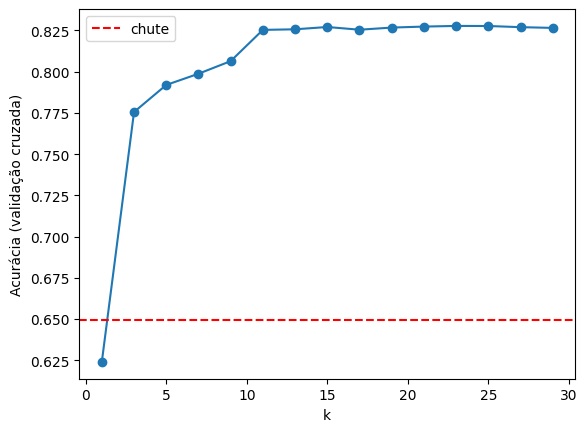

In [21]:
ks = list(range(1, 30, 2))

# amostra de 20 mil acidentes só para a busca do k (mais rápido)
amostra = df.sample(n=20000, random_state=42)
Xa = amostra[X.columns]
ya = amostra["vitima"]
chute_a = (ya == 0).mean()

notas = [cross_val_score(KNeighborsClassifier(n_neighbors=k, n_jobs=-1), Xa, ya, cv=cv).mean() for k in ks]

melhor_k = ks[notas.index(max(notas))]
print(f"Melhor k: {melhor_k} (acurácia {max(notas):.3f} | chute na amostra: {chute_a:.3f})")

plt.plot(ks, notas, marker="o")
plt.axhline(chute_a, color="red", linestyle="--", label="chute")
plt.xlabel("k"); plt.ylabel("Acurácia (validação cruzada)"); plt.legend(); plt.show()

## 9. Predict com 2 acidentes inventados
- **A:** 2 autos, à noite, fim de semana
- **B:** 1 moto e 1 auto, de dia, dia útil

In [22]:
modelo = KNeighborsClassifier(n_neighbors=melhor_k).fit(X, y)

novos = pd.DataFrame(0, index=["A", "B"], columns=X.columns)
novos.loc["A", ["auto", "noite", "fim_de_semana"]] = [2, 1, 1]
novos.loc["B", ["moto", "auto"]] = [1, 1]

previsao = modelo.predict(novos)
prob = modelo.predict_proba(novos)[:, 1]
for nome, p, pr in zip(novos.index, previsao, prob):
    print(f"Acidente {nome}: {'COM vítima' if p == 1 else 'SEM vítima'} (prob. {pr:.0%})")

Acidente A: SEM vítima (prob. 22%)
Acidente B: COM vítima (prob. 74%)


## 10. Conclusões

- **O que mais se associa a vítima:** o tipo de veículo é o fator mais forte. Em média, 35,3% dos acidentes têm vítima, mas esse número sobe para 90,4% quando há bicicleta, 80,3% com patinete e 76,6% com moto. A moto é a mais relevante, porque aparece em 24.771 acidentes (a carroça tem 77,8%, mas só 18 casos). Já táxi (12,7%), caminhão (13,4%) e lotação (21,5%) ficam abaixo da média, e o auto fica em 30,7%. Em geral, quem está sem a proteção de uma carroceria se fere mais.
- **Hora, dia/noite, fim de semana e região:**
  - **Noite:** 45,0% dos acidentes têm vítima, contra 31,5% de dia.
  - **Horário:** o mínimo é às 10h (25,9%) e o máximo às 21h (52,3%). Das 19h às 2h o percentual fica cerca de 45% a 52%.
  - **Fim de semana:** 42,6%, contra 33,6% nos dias úteis. De segunda a sexta o valor é praticamente igual (33,3% a 34,3%), com sábado em 41,9% e domingo em 43,6%.
  - **Região:** Sul tem o maior percentual (40,1%) e Centro o menor (26,8%); Leste (35,4%) e Norte (35,3%) ficam na média.
  - São associações observadas nos dados, não provam causa.
- **Evolução por ano:** o percentual ficou estável entre 2021 e 2024 (35,6% a 37,3%) e caiu em 2025 (33,2%) e 2026 (32,6%). Como 2026 é parcial (dados até outubro), foi usado percentual e não contagem.
- **KNN x chute:** com k=5 e todos os dados, o KNN acertou 81,2% contra 64,7% do chute (sempre "sem vítima"), ou seja, 16,5 pontos percentuais a mais. Na busca do melhor k (amostra de 20 mil acidentes), o melhor foi k=23, com 82,8% contra 65,0% do chute. A diferença entre k=5 e k=23 é pequena (cerca de 1,6 ponto percentual), então o ganho vem do modelo em si e não do ajuste fino do k. Portanto, o modelo supera o chute com folga: veículos, dia/noite e fim de semana ajudam a prever se houve vítima.
- **Predict (acidentes inventados):** o acidente A (2 autos, noite, fim de semana) foi classificado como **sem vítima** (probabilidade de vítima 22%) e o B (moto + auto, dia útil) como **com vítima** (74%). Isso é coerente com a análise: moto aparece com vítima em 76,6% dos casos, e auto sozinho em 30,7%.
- **Limitações:**
  - O modelo usa poucas variáveis (veículos, dia/noite, fim de semana) e muitos acidentes têm características idênticas.
  - A acurácia sozinha pode enganar; não foram medidos recall nem matriz de confusão para a classe "com vítima".
  - O k=5 foi avaliado com todos os dados e a busca do k com uma amostra, mas ambos usam a mesma validação cruzada embaralhada (`StratifiedKFold`), então os resultados são aproximadamente comparáveis.
  - O melhor k foi escolhido na própria validação cruzada, então a nota é levemente otimista.